<a href="https://colab.research.google.com/github/atur0021/MMA3001-Project/blob/main/MMA3001-Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**INPUT PARAMETERS**

In [35]:
csv_name = 'MKII_Hotfire_30_08_2026_Thrust.csv' #file name of thrust data file to use
oxidiser_mass = 5.8 #kg
rocket_dry_mass = 30 #kg
plot_meridian_flight_one = False #boolean

**READING IN DATA FROM GITHUB**

In [36]:
import pandas as pd
import requests
import io
import os
from google.colab import userdata

# Fetch token from Colab Secrets
try:
    token = userdata.get('GH_PAT')
except Exception:
    token = None

# List of all thrust CSV URLs
csv_urls = [
    'https://raw.githubusercontent.com/atur0021/MMA3001-Project/main/MKII_Hotfire_02_05_2026_Thrust.csv',
    'https://raw.githubusercontent.com/atur0021/MMA3001-Project/main/MKII_Hotfire_30_08_2026_Thrust.csv',
    'https://raw.githubusercontent.com/atur0021/MMA3001-Project/main/MKII_Hotfire_06_07_2024_Thrust.csv'
]

# Setup headers for private authentication if token is available
headers = {}
if token:
    headers['Authorization'] = f'token {token}'

# Initialising a dictionary to hold all loaded DataFrames
dfs = {}

for url in csv_urls:
    # Extract a friendly name from the URL to use as a dictionary key
    file_name = url.split('/')[-1]
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()

        # Load the CSV data and store it
        dfs[file_name] = pd.read_csv(io.StringIO(response.text))
        print(f"Successfully loaded: {file_name} ({len(dfs[file_name])} rows)")
    except Exception as e:
        print(f"Error loading {file_name}: {e}")

Successfully loaded: MKII_Hotfire_02_05_2026_Thrust.csv (45044 rows)
Successfully loaded: MKII_Hotfire_30_08_2026_Thrust.csv (7634 rows)
Successfully loaded: MKII_Hotfire_06_07_2024_Thrust.csv (115750 rows)


**TRIMMING THRUST DATA TO REGION OF INTEREST**

--- Dynamic Propellant Mass Correction Complete for MKII_Hotfire_30_08_2026_Thrust.csv ---
Detected Ignition Time: 0.314 s
Pre-ignition Background Offset (Full Wet Mass): 342.80 N
Total weight shift from propellant consumption: 56.88 N
Trimmed data size: 7235 active rows (with negative values zeroed).


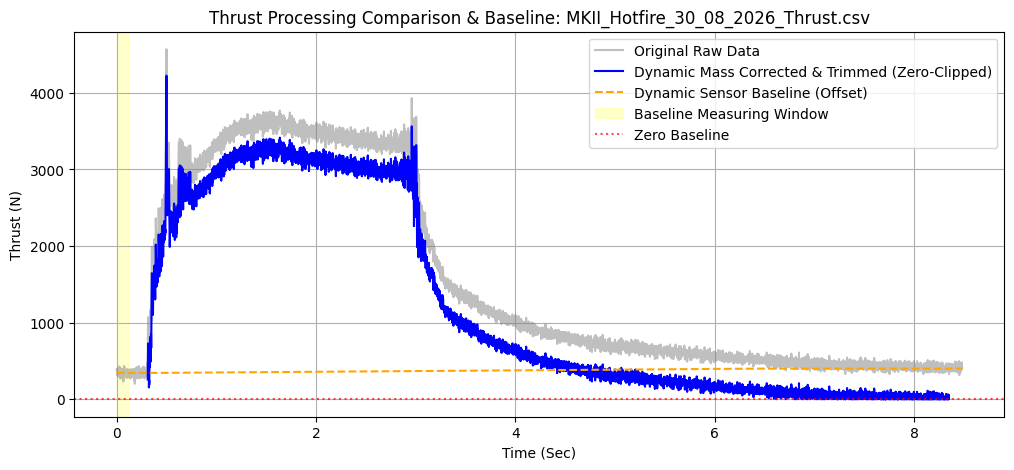

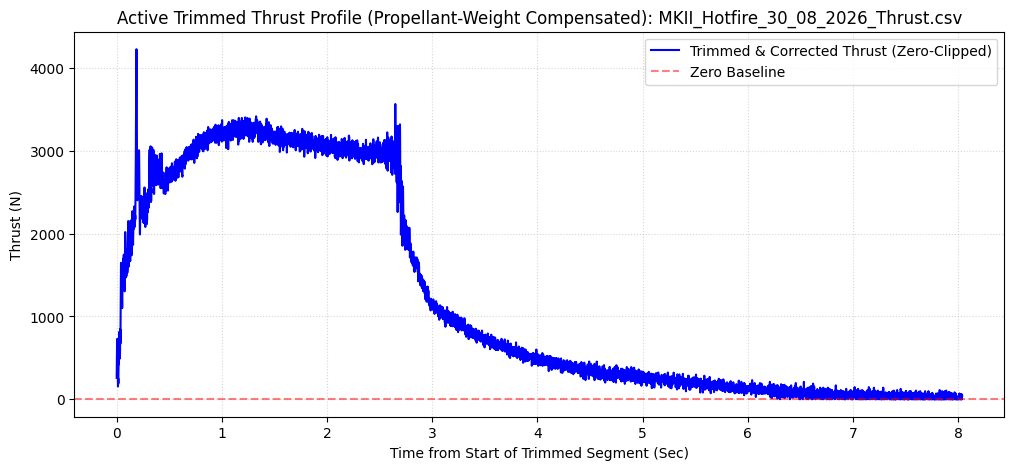

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if csv_name in dfs:
    df = dfs[csv_name].copy()

    # 1. Dynamically find column names
    time_col = [col for col in df.columns if 'time' in col.lower()][0]
    thrust_col = [col for col in df.columns if 'thrust' in col.lower()][0]

    # 2. Safely cast to numeric types
    df[time_col] = pd.to_numeric(df[time_col], errors='coerce')
    df[thrust_col] = pd.to_numeric(df[thrust_col], errors='coerce')
    df = df.dropna(subset=[time_col, thrust_col]).reset_index(drop=True)

    # 3. Find when thrust actually begins (approximate ignition point)
    early_noise_std = df[thrust_col].iloc[:50].std()
    early_noise_mean = df[thrust_col].iloc[:50].mean()

    ignition_threshold = early_noise_mean + (12 * early_noise_std)
    ignition_candidates = df[df[thrust_col] > ignition_threshold].index

    if len(ignition_candidates) > 0:
        raw_ignition_idx = ignition_candidates[0]
        raw_ignition_time = df.loc[raw_ignition_idx, time_col]

        # 4. Calculate baseline from a 2-second window immediately preceding ignition
        time_step = df[time_col].diff().median()
        pts_per_sec = int(1.0 / time_step) if time_step > 0 else 100
        baseline_window_size = int(2.0 * pts_per_sec)

        start_baseline_idx = max(0, raw_ignition_idx - baseline_window_size)
        end_baseline_idx = max(0, raw_ignition_idx - int(0.2 * pts_per_sec))

        baseline_df = df.iloc[start_baseline_idx:end_baseline_idx]
        background_thrust_pre = baseline_df[thrust_col].mean()

        if pd.isna(background_thrust_pre):
            background_thrust_pre = early_noise_mean

        # 5. Apply linear mass depletion correction
        # Standard gravity constant
        g = 9.80665
        burn_duration = 6.0  # seconds

        # Initial offset before burn includes full oxidizer mass loading
        # As oxidizer depletes, the stand gets lighter, shifting the baseline sensor reading upward by (m * g)
        # Therefore, we compensate by linearly subtracting the force of the remaining propellant weight.
        def calculate_dynamic_offset(row):
            t = row[time_col]
            if t < raw_ignition_time:
                # Before ignition, the offset is constant (includes full oxidizer weight)
                return background_thrust_pre
            elif t <= (raw_ignition_time + burn_duration):
                # During the 6-second burn, mass depletes linearly from oxidiser_mass down to 0
                fraction_burnt = (t - raw_ignition_time) / burn_duration
                depleted_force = fraction_burnt * (oxidiser_mass * g)
                return background_thrust_pre + depleted_force
            else:
                # After burn, oxidizer is completely gone, offset remains adjusted
                return background_thrust_pre + (oxidiser_mass * g)

        # Apply the correction
        df['Dynamic_Offset'] = df.apply(calculate_dynamic_offset, axis=1)
        df['Thrust_Corrected'] = df[thrust_col] - df['Dynamic_Offset']

        # 6. Locate the full active region using corrected values
        max_corrected_thrust = df['Thrust_Corrected'].max()
        active_threshold = 0.05 * max_corrected_thrust
        active_indices = df[df['Thrust_Corrected'] > active_threshold].index

        # Tightened start buffer to 0.00 seconds so it starts almost immediately as the thrust goes above baseline
        start_idx = max(0, active_indices[0] - int(0.00 * pts_per_sec))
        end_idx = min(len(df) - 1, active_indices[-1] + int(2.0 * pts_per_sec))

        df_trimmed_dynamic = df.iloc[start_idx:end_idx].copy()

        # Force any negative corrected thrust values in the trimmed range to zero
        df_trimmed_dynamic['Thrust_Corrected'] = df_trimmed_dynamic['Thrust_Corrected'].clip(lower=0.0)

        # Shift the time axis of the trimmed data to start exactly at t = 0
        start_time = df_trimmed_dynamic[time_col].min()
        df_trimmed_dynamic['Time_Shifted'] = df_trimmed_dynamic[time_col] - start_time

        print(f"--- Dynamic Propellant Mass Correction Complete for {csv_name} ---")
        print(f"Detected Ignition Time: {raw_ignition_time:.3f} s")
        print(f"Pre-ignition Background Offset (Full Wet Mass): {background_thrust_pre:.2f} N")
        print(f"Total weight shift from propellant consumption: {oxidiser_mass * g:.2f} N")
        print(f"Trimmed data size: {len(df_trimmed_dynamic)} active rows (with negative values zeroed).")

        # 7. Plot original raw data vs corrected baseline full window comparison
        plt.figure(figsize=(12, 5))
        plt.plot(df[time_col], df[thrust_col], label='Original Raw Data', color='gray', alpha=0.5)
        plt.plot(df_trimmed_dynamic[time_col], df_trimmed_dynamic['Thrust_Corrected'], label='Dynamic Mass Corrected & Trimmed (Zero-Clipped)', color='blue')
        plt.plot(df[time_col], df['Dynamic_Offset'], label='Dynamic Sensor Baseline (Offset)', color='orange', linestyle='--')
        plt.axvspan(df.loc[start_baseline_idx, time_col], df.loc[end_baseline_idx, time_col],
                    color='yellow', alpha=0.2, label='Baseline Measuring Window')
        plt.axhline(0, color='red', linestyle=':', alpha=0.7, label='Zero Baseline')
        plt.xlabel('Time (Sec)')
        plt.ylabel('Thrust (N)')
        plt.title(f'Thrust Processing Comparison & Baseline: {csv_name}')
        plt.legend()
        plt.grid(True)
        plt.show()

        # 8. Plot ONLY the new trimmed and corrected active dataset starting at t = 0
        plt.figure(figsize=(12, 5))
        plt.plot(df_trimmed_dynamic['Time_Shifted'], df_trimmed_dynamic['Thrust_Corrected'], label='Trimmed & Corrected Thrust (Zero-Clipped)', color='blue', linewidth=1.5)
        plt.axhline(0, color='red', linestyle='--', alpha=0.5, label='Zero Baseline')
        plt.xlabel('Time from Start of Trimmed Segment (Sec)')
        plt.ylabel('Thrust (N)')
        plt.title(f'Active Trimmed Thrust Profile (Propellant-Weight Compensated): {csv_name}')
        plt.legend()
        plt.grid(True, which='both', linestyle=':', alpha=0.5)
        plt.show()

        # Save for downstream calculations
        active_df = df_trimmed_dynamic
    else:
        print("Could not automatically identify any ignition spike above noise threshold.")
else:
    print(f"Error: '{csv_name}' was not found in loaded datasets.")

**FITTING A REGRESSION MODEL**

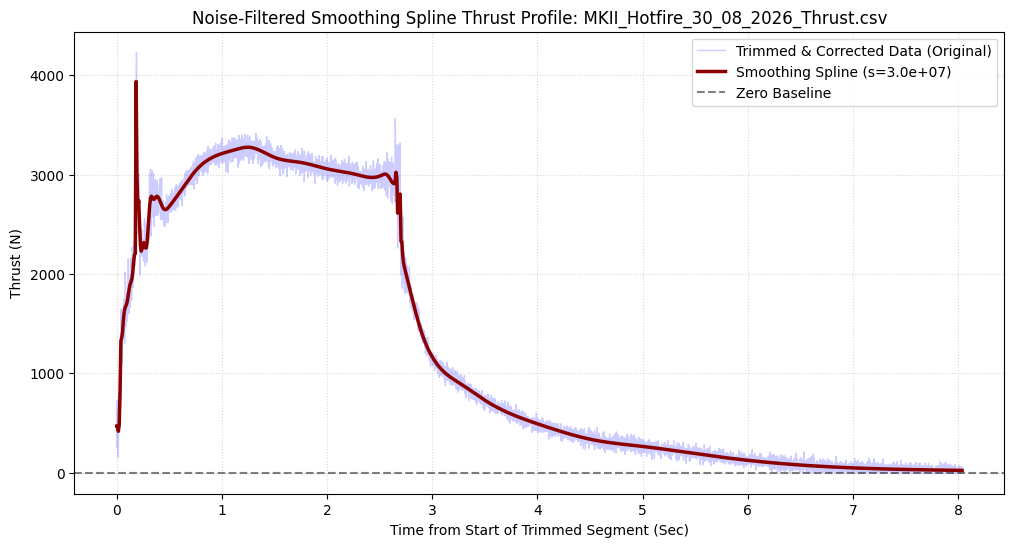

In [38]:
from scipy.interpolate import UnivariateSpline
import numpy as np
import matplotlib.pyplot as plt

if 'active_df' in globals() and active_df is not None:
    # 1. Extract the shifted time and corrected thrust
    x = active_df['Time_Shifted'].values
    y = active_df['Thrust_Corrected'].values

    # 2. To avoid duplicate x values, aggregate them by mean
    unique_data = active_df.groupby('Time_Shifted')['Thrust_Corrected'].mean().reset_index()
    x_unique = unique_data['Time_Shifted'].values
    y_unique = unique_data['Thrust_Corrected'].values

    # --- ADJUST SMOOTHING HERE ---
    # The 'smoothing_factor' (s) determines how close the spline stays to your noisy points.
    # - s = 0: Exact interpolation (passes through every point, like cubic spline).
    # - s = very large: A rigid, least-squares line fit.
    # We set a starting value that balances filtering noise with keeping physical peaks.
    smoothing_factor = 3e7  # Increase this to get a smoother curve; decrease it to match data closer

    # 3. Fit a Smoothing Spline (does NOT have to pass through every point)
    spline = UnivariateSpline(x_unique, y_unique, s=smoothing_factor)

    # 4. Generate points for plotting
    x_smooth = np.linspace(x_unique.min(), x_unique.max(), 1000)
    y_smooth = spline(x_smooth)

    # 5. Plot the original trimmed data alongside the Smoothing Spline profile
    plt.figure(figsize=(12, 6))
    plt.plot(x, y, label='Trimmed & Corrected Data (Original)', color='blue', alpha=0.2, linewidth=1)
    plt.plot(x_smooth, y_smooth, label=f'Smoothing Spline (s={smoothing_factor:.1e})', color='darkred', linewidth=2.5)
    plt.axhline(0, color='black', linestyle='--', alpha=0.5, label='Zero Baseline')
    plt.xlabel('Time from Start of Trimmed Segment (Sec)')
    plt.ylabel('Thrust (N)')
    plt.title(f'Noise-Filtered Smoothing Spline Thrust Profile: {csv_name}')
    plt.legend()
    plt.grid(True, which='both', linestyle=':', alpha=0.5)
    plt.show()

    # Store the smoothed values in the workspace
    smoothed_time = x_smooth
    smoothed_thrust = y_smooth
else:
    print("Error: 'active_df' is not defined. Please make sure the previous trimming cell has run successfully.")

In [39]:
if 'spline' in globals() and 'x_unique' in globals() and 'y_unique' in globals():
    # Evaluate the spline at the original unique time points
    y_pred = spline(x_unique)

    # Calculate Residual Sum of Squares (RSS) and Total Sum of Squares (TSS)
    mean_y = np.mean(y_unique)
    ss_res = np.sum((y_unique - y_pred) ** 2)
    ss_tot = np.sum((y_unique - mean_y) ** 2)

    # Compute R-squared
    r_squared = 1 - (ss_res / ss_tot)

    print(f"--- Spline Fit Quality Metrics ---")
    print(f"Smoothing Factor (s): {smoothing_factor:.1e}")
    print(f"R-squared (R²): {r_squared:.6f}")
else:
    print("Error: Spline model or data points not found in workspace. Please run the regression model cell first.")

--- Spline Fit Quality Metrics ---
Smoothing Factor (s): 3.0e+07
R-squared (R²): 0.997494
